In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


## ✳**Terceira etapa do pré processamento** :

Janelamento, normalização e formatação

Entregas desta etapa (usadas na fase de modelagem):

- **`janelar`** → corta os sinais inteiros em janelas e guarda, para cada janela, o **`id_sinal`** (índice 0–499 do sinal de origem)
- **`ajustar_normalizacao` / `aplicar_normalizacao`** → z-score com parâmetros estimados **só nas janelas de ajuste** (equivalente a `scaler.fit` / `scaler.transform`)
- **`preparar_dados(idx_fit, idx_val, idx_teste)`** → pipeline completo: devolve os DataLoaders `fit`, `val` e `teste`, com lotes no formato **(lote, canais, amostras) = (64, 1, 512)**, rótulos 0–4 (A–E) e o `id_sinal` de cada janela
- **`agregar_por_sinal`** → junta as previsões das janelas em uma previsão por sinal inteiro (métrica por sinal)
- tudo salvo em `Projet Thématique/processado/etapa3_janelas.npz` (divisão padrão = fold 0), quando `SALVAR = True`

A etapa só precisa do `etapa2_filtrado_split.npz`: dá para rodar a partir daqui sem refazer as etapas 1 e 2.

In [ ]:
# ----- etapa 3: janelamento, normalização e formatação -----
# só depende do arquivo salvo na etapa 2 (o drive precisa estar montado, célula da etapa 1)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset, DataLoader
from pathlib import Path

pasta_proj = Path('/content/drive/MyDrive/Projet Thématique')
pasta_proc = pasta_proj / "processado"
pasta_fig = pasta_proj / "figuras"

d = np.load(pasta_proc / "etapa2_filtrado_split.npz")
sinais_filtrados, rotulos, ids = d["sinais_filtrados"], d["rotulos"], d["ids"]
idx_treino, idx_teste = d["idx_treino"], d["idx_teste"]
fv = d["fold_validacao"]
folds = [(idx_treino[fv[idx_treino] != k], np.where(fv == k)[0]) for k in range(5)]
freq, SEED = float(d["fs"]), int(d["seed"])  # 173,61 Hz e 42, os mesmos da etapa 2

print("sinais_filtrados:", sinais_filtrados.shape, "| treino:", len(idx_treino), "| teste:", len(idx_teste))

Exception ignored in: <function NpzFile.__del__ at 0x7f0fd0bf3100>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/numpy/lib/_npyio_impl.py", line 230, in __del__
    self.close()
  File "/usr/local/lib/python3.13/dist-packages/numpy/lib/_npyio_impl.py", line 225, in close
    self.fid.close()
OSError: [Errno 107] Transport endpoint is not connected


sinais_filtrados: (500, 4096) | treino: 400 | teste: 100


### Parâmetros

Todos os parâmetros da etapa ficam numa célula só, para o grupo testar outras escolhas mudando uma linha.

- **Janela de 512 amostras (≈ 2,95 s)**: como 4096 = 8 × 512, as janelas sem sobreposição cobrem o sinal inteiro sem sobrar amostra. Uma janela de ~3 s contém vários ciclos de todas as bandas, inclusive delta (0,5–4 Hz), e fica dentro da faixa de 1–4 s usada nos trabalhos com o Bonn.
- **Sobreposição de 50 % só no ajuste** (passo 256 → 15 janelas por sinal): dá mais exemplos para as redes treinarem (data augmentation). Na validação e no teste o passo é 512 (8 janelas por sinal, sem sobreposição): janelas sobrepostas não trazem informação nova e contariam o mesmo trecho duas vezes na métrica.
- **Divisão padrão = fold 0** da etapa 2: 320 sinais para ajustar, 80 para validação e 100 de teste.
- **Rótulos** A–E viram 0–4, porque as redes (e a `CrossEntropyLoss`) trabalham com inteiros.
- **`SALVAR`**: `False` enquanto for rascunho, para não gravar nada na pasta do grupo.

In [ ]:
CLASSES = np.array(["A", "B", "C", "D", "E"])  # posição = rótulo numérico (A = 0, …, E = 4)

TAM_JANELA = 512      # amostras por janela (512 / 173,61 Hz ≈ 2,95 s)
PASSO_FIT = 256       # passo no ajuste → 50 % de sobreposição (15 janelas por sinal)
PASSO_AVAL = 512      # passo na validação e no teste → sem sobreposição (8 janelas por sinal)
MODO_NORM = "global"  # "global" (média e desvio do ajuste) ou "janela" (z-score de cada janela)
BATCH = 64
FOLD_PADRAO = 0
SALVAR = False        # True → grava a figura e o .npz no drive do grupo (versão final)

y_sinal = np.searchsorted(CLASSES, rotulos)  # rótulo numérico de cada um dos 500 sinais
idx_fit, idx_val = folds[FOLD_PADRAO]

print(f"janela: {TAM_JANELA} amostras = {TAM_JANELA / freq:.2f} s")
print(f"sinais → ajuste: {len(idx_fit)} | validação: {len(idx_val)} | teste: {len(idx_teste)}")

janela: 512 amostras = 2.95 s
sinais → ajuste: 320 | validação: 80 | teste: 100


### Janelamento

`janelar` recebe os **índices dos sinais inteiros** (nunca janelas sorteadas) e corta cada sinal em janelas de `tam` amostras, andando `passo` amostras de uma janela para a outra. Cada janela herda o rótulo e o lado da divisão (ajuste, validação ou teste) do sinal de onde saiu. O `id_sinal` de cada janela é guardado para:

1. conferir que nenhum sinal tem janelas em dois lados da divisão (anti-leakage);
2. juntar as previsões das janelas por sinal no final (métrica por sinal).

Número de janelas por sinal: ⌊(4096 − tam) / passo⌋ + 1.

In [ ]:
def janelar(sinais, idx, tam=TAM_JANELA, passo=PASSO_FIT):
    # corta os sinais idx em janelas de tam amostras, deslocando passo amostras a cada janela
    # devolve janelas (n_janelas, tam) e id_sinal (n_janelas,) com o índice (0–499) do sinal de origem
    idx = np.asarray(idx, dtype=int)
    inicios = np.arange(0, sinais.shape[1] - tam + 1, passo)
    janelas = sinais[idx][:, inicios[:, None] + np.arange(tam)]  # (n_sinais, janelas_por_sinal, tam)
    id_sinal = np.repeat(idx, len(inicios))
    return janelas.reshape(-1, tam).astype(np.float32), id_sinal

J_fit, id_fit = janelar(sinais_filtrados, idx_fit, passo=PASSO_FIT)
J_val, id_val = janelar(sinais_filtrados, idx_val, passo=PASSO_AVAL)
J_teste, id_teste = janelar(sinais_filtrados, idx_teste, passo=PASSO_AVAL)

contagem = pd.DataFrame({
    "ajuste": pd.Series(rotulos[id_fit]).value_counts(),
    "validação": pd.Series(rotulos[id_val]).value_counts(),
    "teste": pd.Series(rotulos[id_teste]).value_counts(),
}).sort_index()
contagem.loc["total"] = contagem.sum()
print(contagem)
print("\nformato das janelas → ajuste:", J_fit.shape, "| validação:", J_val.shape, "| teste:", J_teste.shape)

       ajuste  validação  teste
A         960        128    160
B         960        128    160
C         960        128    160
D         960        128    160
E         960        128    160
total    4800        640    800

formato das janelas → ajuste: (4800, 512) | validação: (640, 512) | teste: (800, 512)


Verificações do janelamento:

1. **quantidade**: cada sinal gera exatamente ⌊(4096 − tam) / passo⌋ + 1 janelas;
2. **anti-leakage**: nenhum `id_sinal` aparece em dois lados da divisão;
3. **fidelidade**: sem sobreposição, as janelas de um sinal coladas em ordem reconstroem o sinal original (nada foi perdido nem embaralhado dentro do sinal);
4. **sobreposição**: no ajuste, a 2ª janela começa `PASSO_FIT` amostras depois da 1ª.

In [ ]:
def janelas_por_sinal(passo, tam=TAM_JANELA, n_amostras=sinais_filtrados.shape[1]):
    return (n_amostras - tam) // passo + 1

# 1) quantidade
assert len(J_fit) == len(idx_fit) * janelas_por_sinal(PASSO_FIT), "número de janelas de ajuste errado"
assert len(J_val) == len(idx_val) * janelas_por_sinal(PASSO_AVAL), "número de janelas de validação errado"
assert len(J_teste) == len(idx_teste) * janelas_por_sinal(PASSO_AVAL), "número de janelas de teste errado"

# 2) anti-leakage: nenhum sinal com janelas em dois lados da divisão
assert np.intersect1d(id_fit, id_val).size == 0, "sinal com janelas no ajuste e na validação"
assert np.intersect1d(id_fit, id_teste).size == 0, "sinal com janelas no ajuste e no teste"
assert np.intersect1d(id_val, id_teste).size == 0, "sinal com janelas na validação e no teste"

# 3) fidelidade: sem sobreposição, colar as janelas de um sinal reconstrói o sinal
if PASSO_AVAL == TAM_JANELA and sinais_filtrados.shape[1] % TAM_JANELA == 0:
    for i in idx_teste:
        assert np.allclose(J_teste[id_teste == i].ravel(), sinais_filtrados[i], atol=1e-3), f"sinal {i} mal reconstruído"

# 4) sobreposição no ajuste
if PASSO_FIT < TAM_JANELA:
    assert np.array_equal(J_fit[0, PASSO_FIT:], J_fit[1, :TAM_JANELA - PASSO_FIT]), "sobreposição incorreta"

print("OK: contagens corretas, nenhum sinal em dois lados da divisão e janelas fiéis ao sinal original")

OK: contagens corretas, nenhum sinal em dois lados da divisão e janelas fiéis ao sinal original


### Normalização

As amplitudes dos conjuntos diferem em ordens de grandeza (gráfico 02 da etapa 1), então as redes precisam receber os dados numa escala comum. Há duas opções, escolhidas por `MODO_NORM`:

- **global**: um único par média/desvio (o sinal tem um canal só), estimado **só nas janelas de ajuste** e aplicado no ajuste, na validação e no teste. É uma mudança de escala linear: as diferenças de amplitude entre os conjuntos **continuam** nos dados e a rede pode usá-las. Ponto de atenção (Ata 1): A e B são de escalpo e C, D e E são intracranianos, então parte da diferença de amplitude vem do tipo de eletrodo, e não da patologia.
- **janela**: cada janela vira média 0 e desvio 1 com a **própria** média e desvio. Nada é estimado a partir do conjunto de dados (não tem como vazar) e a amplitude absoluta desaparece: a rede é obrigada a aprender a **forma** do sinal (ritmos, espículas, ondas lentas).

Comparar os dois modos no mesmo modelo é uma boa análise para o relatório: mostra quanto do desempenho vem só da amplitude. As funções seguem a regra anti-leakage da etapa 2: **ajustar** só com o ajuste, **aplicar** em tudo.

In [ ]:
def ajustar_normalizacao(janelas_fit, modo=MODO_NORM):
    # estima os parâmetros SÓ com as janelas de ajuste (equivalente ao scaler.fit)
    if modo == "global":
      media = float(janelas_fit.mean(dtype=np.float64))
      desvio = float(janelas_fit.std(dtype=np.float64))
      return {
        "media": media,
        "desvio": max(desvio, 1e-8)
      }
    if modo == "janela":
      return {}  # cada janela usa a própria média e desvio: nada a estimar
    raise ValueError(f"modo de normalização desconhecido: {modo!r} (use 'global' ou 'janela')")


def aplicar_normalizacao(janelas, params, modo=MODO_NORM):
    # aplica a normalização (equivalente ao scaler.transform) e devolve float32
    if modo == "global":
        return ((janelas - params["media"]) / params["desvio"]).astype(np.float32)
    media = janelas.mean(axis=1, keepdims=True)
    desvio = janelas.std(axis=1, keepdims=True)
    return ((janelas - media) / (desvio + 1e-8)).astype(np.float32)

params = ajustar_normalizacao(J_fit)
X_fit, X_val, X_teste = (aplicar_normalizacao(J, params) for J in (J_fit, J_val, J_teste))
print("modo:", MODO_NORM, "| parâmetros estimados no ajuste (µV):", {k: round(v, 2) for k, v in params.items()})

modo: global | parâmetros estimados no ajuste (µV): {'media': -7.31, 'desvio': 158.2}


Verificação: o ajuste tem que sair com média 0 e desvio 1. Validação e teste usam os parâmetros do ajuste, então ficam **perto** de 0 e 1, mas não exatamente (é o esperado, e é a prova de que não houve vazamento). O desvio médio por conjunto mostra se a diferença de amplitude entre A–E continua nos dados (modo global) ou não (modo janela).

In [ ]:
resumo = pd.DataFrame({
    nome: {"média": X.mean(dtype=np.float64), "desvio": X.std(dtype=np.float64)}
    for nome, X in [("ajuste", X_fit), ("validação", X_val), ("teste", X_teste)]
}).T.round(3)
print(resumo)

print("\ndesvio médio das janelas de ajuste por conjunto, depois da normalização:")
print(pd.Series(X_fit.std(axis=1)).groupby(rotulos[id_fit]).mean().round(3).to_string())

if MODO_NORM == "global":
    assert abs(X_fit.mean(dtype=np.float64)) < 1e-3 and abs(X_fit.std(dtype=np.float64) - 1) < 1e-3, \
        "o ajuste não ficou com média 0 e desvio 1"
else:
    assert np.allclose(X_fit.mean(axis=1), 0, atol=1e-4) and np.allclose(X_fit.std(axis=1), 1, atol=1e-3), \
        "alguma janela não ficou com média 0 e desvio 1"
print("\nOK: ajuste com média 0 e desvio 1; validação e teste normalizados com os parâmetros do ajuste")

           média  desvio
ajuste    -0.000   1.000
validação  0.002   1.085
teste     -0.014   1.126

desvio médio das janelas de ajuste por conjunto, depois da normalização:
A    0.256
B    0.383
C    0.318
D    0.390
E    1.839

OK: ajuste com média 0 e desvio 1; validação e teste normalizados com os parâmetros do ajuste


Figura para o relatório: a mesma janela de cada conjunto em µV (saída do janelamento), com normalização global e com normalização por janela. Na global, as proporções entre os conjuntos continuam (E bem maior que A); por janela, todas ficam na mesma escala e só a forma muda.

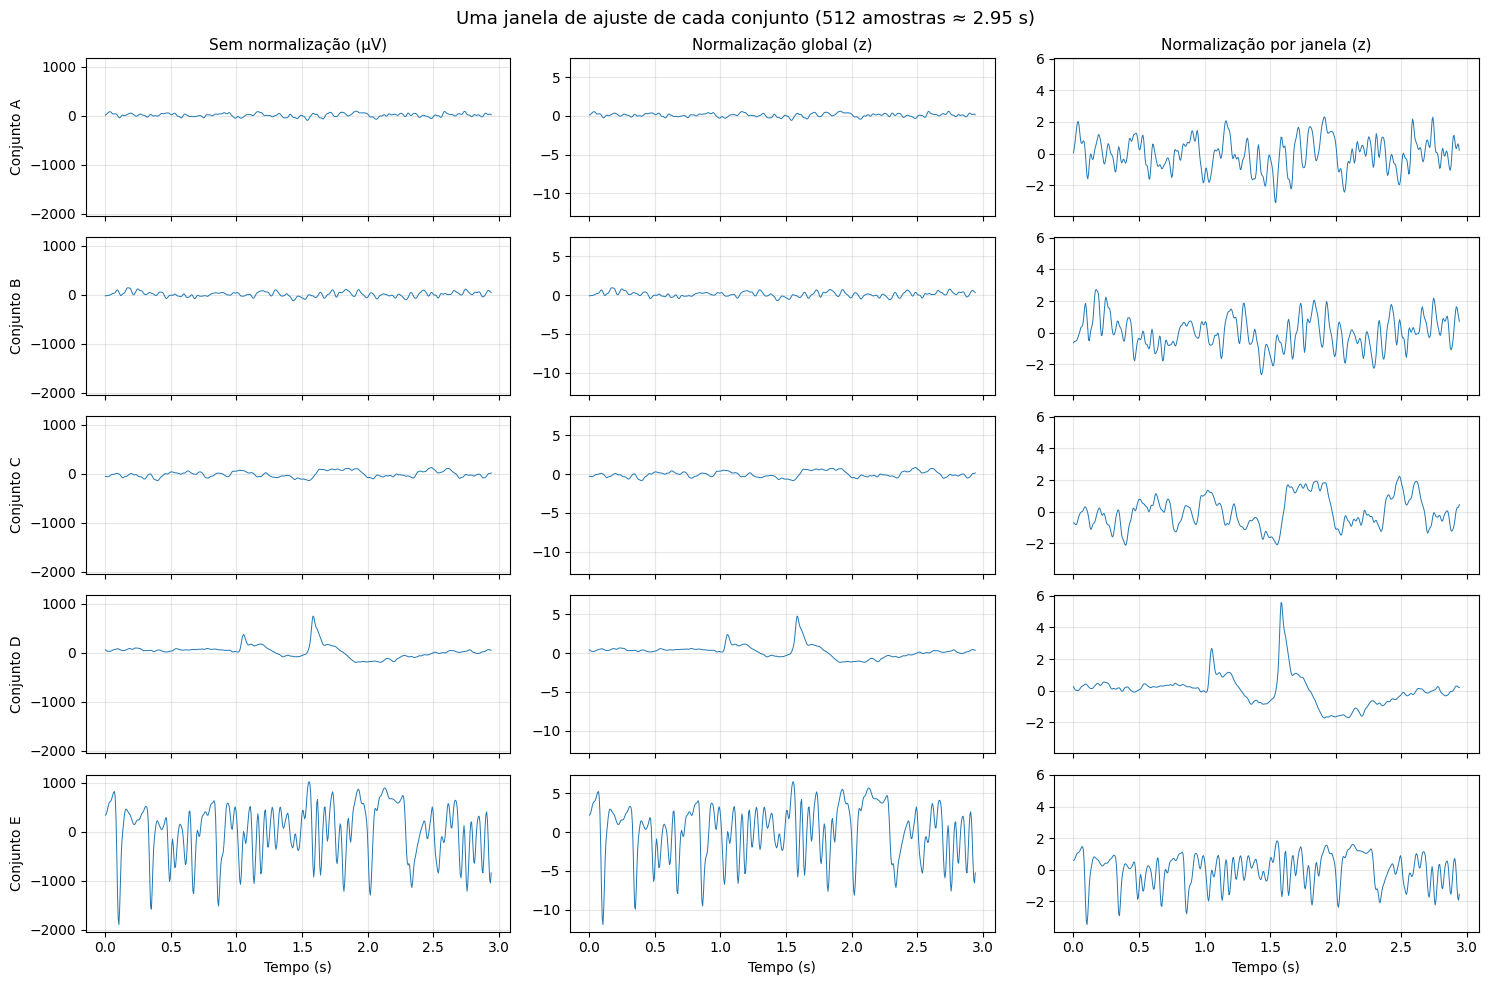

In [ ]:
params_global = ajustar_normalizacao(J_fit, "global")
t_jan = np.arange(TAM_JANELA) / freq
versoes = [
    ("Sem normalização (µV)", J_fit),
    ("Normalização global (z)", aplicar_normalizacao(J_fit, params_global, "global")),
    ("Normalização por janela (z)", aplicar_normalizacao(J_fit, {}, "janela")),
]

fig, axes = plt.subplots(5, 3, figsize=(15, 10), sharex=True, sharey="col")
for linha, label in enumerate(CLASSES):
    k = np.flatnonzero(rotulos[id_fit] == label)[0]  # primeira janela de ajuste do conjunto
    for col, (titulo, J) in enumerate(versoes):
        ax = axes[linha, col]
        ax.plot(t_jan, J[k], lw=0.7)
        ax.grid(alpha=0.3)
        if linha == 0:
            ax.set_title(titulo, fontsize=11)
    axes[linha, 0].set_ylabel(f"Conjunto {label}")
for ax in axes[-1]:
    ax.set_xlabel("Tempo (s)")
fig.suptitle(f"Uma janela de ajuste de cada conjunto ({TAM_JANELA} amostras ≈ {TAM_JANELA / freq:.2f} s)", fontsize=13)
plt.tight_layout()
if SALVAR:
    plt.savefig(pasta_fig / "09_janelas_normalizacao.png", dpi=300)
plt.show()

### Dataset e DataLoader

Formato combinado na Ata 2: **(n, canais, amostras)**. Cada item do `JanelasEEG` devolve `(x, y, id_sinal)`:

- `x`: tensor float32 de formato (1, 512) → em lote, **(64, 1, 512)**;
- `y`: inteiro de 0 a 4 (A–E), o formato que a `nn.CrossEntropyLoss` espera;
- `id_sinal`: índice do sinal de origem, para a métrica por sinal.

Como cada rede lê o mesmo lote:

- **CNN 1D** (`nn.Conv1d`): usa `x` direto, (lote, canais, amostras);
- **LSTM** (`nn.LSTM(batch_first=True)`): espera (lote, passos, atributos) → `x.permute(0, 2, 1)` = (64, 512, 1);
- **Transformer**: 512 passos de 1 valor deixam a atenção cara (512² pares) e cada token com pouca informação. Sugestão: agrupar em *patches* de 16 amostras → `x.reshape(lote, 32, 16)` = 32 tokens de 16 valores (ou uma `Conv1d` na entrada fazendo o mesmo papel).

O DataLoader de ajuste embaralha com semente fixa (`SEED`); os de validação e teste não embaralham (ordem fixa, mais fácil de agregar por sinal e de comparar modelos).

In [ ]:
class JanelasEEG(Dataset):
    # janelas normalizadas no formato (n, canais, amostras) + rótulo 0–4 + id do sinal de origem
    def __init__(self, janelas, y, id_sinal):
        self.x = torch.from_numpy(np.ascontiguousarray(janelas[:, np.newaxis, :], dtype=np.float32))
        self.y = torch.from_numpy(np.asarray(y, dtype=np.int64))
        self.id_sinal = torch.from_numpy(np.asarray(id_sinal, dtype=np.int64))

    def __len__(self):
        return len(self.y)

    def __getitem__(self, k):
        return self.x[k], self.y[k], self.id_sinal[k]


def preparar_dados(idx_fit, idx_val, idx_teste, tam=TAM_JANELA, passo_fit=PASSO_FIT,
                   passo_aval=PASSO_AVAL, modo=MODO_NORM, batch=BATCH, seed=SEED):
    # pipeline completo da etapa 3 para UMA divisão de sinais inteiros:
    # janela → ajusta a normalização só no ajuste → aplica nos três → DataLoaders
    # idx_val pode ser None (modelo final: ajusta em todo o idx_treino e avalia no teste)
    partes = {"fit": (idx_fit, passo_fit), "val": (idx_val, passo_aval), "teste": (idx_teste, passo_aval)}
    partes = {nome: p for nome, p in partes.items() if p[0] is not None}

    janelas, origem = {}, {}
    for nome, (idx, passo) in partes.items():
        janelas[nome], origem[nome] = janelar(sinais_filtrados, idx, tam, passo)

    params = ajustar_normalizacao(janelas["fit"], modo)

    loaders = {}
    for nome in partes:
        ds = JanelasEEG(aplicar_normalizacao(janelas[nome], params, modo), y_sinal[origem[nome]], origem[nome])
        embaralhar = nome == "fit"
        gerador = torch.Generator().manual_seed(seed) if embaralhar else None
        loaders[nome] = DataLoader(ds, batch_size=batch, shuffle=embaralhar, generator=gerador)
    return loaders, params

Como usar nas próximas fases:

```python
loaders, params = preparar_dados(*folds[0], idx_teste)                 # divisão padrão: 320 / 80 / 100 sinais
for k, (tr, va) in enumerate(folds):                                    # validação cruzada (normalização refeita em cada fold)
    loaders_k, params_k = preparar_dados(tr, va, idx_teste)
loaders_final, params_final = preparar_dados(idx_treino, None, idx_teste)  # modelo final: 400 sinais de ajuste
```

Teste abaixo: um lote passa pelas camadas de entrada das três redes (CNN 1D, LSTM e Transformer), confirmando que o formato serve para todas, e o embaralhamento é reprodutível com a mesma semente.

In [ ]:
loaders, params = preparar_dados(idx_fit, idx_val, idx_teste)

x, y, id_lote = next(iter(loaders["fit"]))
print("lote de ajuste → x:", tuple(x.shape), x.dtype, "| y:", tuple(y.shape), y.dtype, "| id_sinal:", tuple(id_lote.shape))
print("janelas por DataLoader:", {nome: len(dl.dataset) for nome, dl in loaders.items()})

# o mesmo lote nas camadas de entrada de cada rede
torch.manual_seed(SEED)
cnn = torch.nn.Conv1d(in_channels=1, out_channels=8, kernel_size=7, padding=3)
lstm = torch.nn.LSTM(input_size=1, hidden_size=16, batch_first=True)
transformer = torch.nn.TransformerEncoderLayer(d_model=16, nhead=4, batch_first=True)
with torch.no_grad():
    saida_cnn = cnn(x)                                # entrada (lote, 1, 512)
    saida_lstm, _ = lstm(x.permute(0, 2, 1))          # entrada (lote, 512, 1)
    saida_tr = transformer(x.reshape(len(x), -1, 16))  # entrada (lote, 32 tokens, 16)
print("saídas → CNN 1D:", tuple(saida_cnn.shape), "| LSTM:", tuple(saida_lstm.shape), "| Transformer:", tuple(saida_tr.shape))

assert x.shape[1:] == (1, TAM_JANELA) and x.dtype == torch.float32, "formato de x errado"
assert y.dtype == torch.int64 and 0 <= int(y.min()) and int(y.max()) <= 4, "rótulos fora de 0–4"
assert torch.equal(y, torch.from_numpy(y_sinal[id_lote.numpy()])), "rótulo não bate com o sinal de origem"

# reprodutibilidade: mesma semente → mesma ordem de embaralhamento
_, _, id_a = next(iter(preparar_dados(idx_fit, idx_val, idx_teste)[0]["fit"]))
_, _, id_b = next(iter(preparar_dados(idx_fit, idx_val, idx_teste)[0]["fit"]))
assert torch.equal(id_a, id_b), "embaralhamento não é reprodutível"
print("\nOK: formato (lote, 1, 512) float32, rótulos 0–4 coerentes com o sinal de origem e embaralhamento reprodutível")

lote de ajuste → x: (64, 1, 512) torch.float32 | y: (64,) torch.int64 | id_sinal: (64,)
janelas por DataLoader: {'fit': 4800, 'val': 640, 'teste': 800}
saídas → CNN 1D: (64, 8, 512) | LSTM: (64, 512, 16) | Transformer: (64, 32, 16)

OK: formato (lote, 1, 512) float32, rótulos 0–4 coerentes com o sinal de origem e embaralhamento reprodutível


### Métrica por sinal

As redes classificam **janelas**, mas o diagnóstico é sobre o **sinal inteiro** (23,6 s). `agregar_por_sinal` tira a média das probabilidades das 8 janelas de cada sinal de validação ou teste e devolve uma previsão por sinal. Assim, todos os modelos podem ser comparados do mesmo jeito, com as duas acurácias: por janela e por sinal.

Teste abaixo com probabilidades **simuladas** (os modelos de verdade vêm na próxima fase): um "modelo" ruidoso que erra parte das janelas, mas acerta mais quando junta as 8 janelas de cada sinal.

In [ ]:
def agregar_por_sinal(probs, id_sinal):
    # média das probabilidades das janelas de cada sinal → uma previsão por sinal inteiro
    # probs: (n_janelas, 5), saída softmax do modelo | id_sinal: (n_janelas,)
    # devolve os ids dos sinais (n_sinais,) e as probabilidades médias (n_sinais, 5)
    probs, id_sinal = np.asarray(probs), np.asarray(id_sinal)
    ids_unicos, posicao = np.unique(id_sinal, return_inverse=True)
    soma = np.zeros((len(ids_unicos), probs.shape[1]))
    np.add.at(soma, posicao, probs)
    return ids_unicos, soma / np.bincount(posicao)[:, None]

# teste com um "modelo" simulado e ruidoso
rng = np.random.default_rng(SEED)
id_janelas = loaders["teste"].dataset.id_sinal.numpy()
y_janelas = y_sinal[id_janelas]
probs_sim = rng.dirichlet(np.ones(5), size=len(y_janelas))
probs_sim[np.arange(len(y_janelas)), y_janelas] += 0.2
probs_sim /= probs_sim.sum(axis=1, keepdims=True)

ids_sinais, probs_sinal = agregar_por_sinal(probs_sim, id_janelas)
acc_janela = (probs_sim.argmax(axis=1) == y_janelas).mean()
acc_sinal = (probs_sinal.argmax(axis=1) == y_sinal[ids_sinais]).mean()
print(f"(simulação) acurácia por janela: {acc_janela:.1%} | por sinal: {acc_sinal:.1%} ({len(ids_sinais)} sinais)")

assert len(ids_sinais) == len(idx_teste) and np.allclose(probs_sinal.sum(axis=1), 1), "agregação incorreta"
print("OK: uma previsão por sinal de teste, com probabilidades que somam 1")

(simulação) acurácia por janela: 42.9% | por sinal: 96.0% (100 sinais)
OK: uma previsão por sinal de teste, com probabilidades que somam 1


### Salvando as entregas

Com `SALVAR = True`, grava as janelas já normalizadas da divisão padrão (fold 0), junto com os parâmetros usados (janela, passos, modo e média/desvio da normalização), para a fase de modelagem começar sem refazer nada. No rascunho fica `False`, para não mexer na pasta do grupo.

In [ ]:
conteudo = {}
for nome, dl in loaders.items():
    conteudo[f"X_{nome}"] = dl.dataset.x.numpy()
    conteudo[f"y_{nome}"] = dl.dataset.y.numpy()
    conteudo[f"id_sinal_{nome}"] = dl.dataset.id_sinal.numpy()
conteudo.update(
    tam_janela=TAM_JANELA, passo_fit=PASSO_FIT, passo_aval=PASSO_AVAL, modo_norm=MODO_NORM,
    media=params.get("media", np.nan), desvio=params.get("desvio", np.nan),
    fold=FOLD_PADRAO, seed=SEED, classes=CLASSES,
)
for chave in ["X_fit", "X_val", "X_teste"]:
    print(f"{chave}: {conteudo[chave].shape}")

arquivo = pasta_proc / "etapa3_janelas.npz"
if SALVAR:
    np.savez_compressed(arquivo, **conteudo)
    print("salvo em", arquivo.relative_to(pasta_proj.parent), f"({arquivo.stat().st_size / 1e6:.1f} MB)")
else:
    print("\nSALVAR = False → nada foi gravado no drive (rascunho)")

X_fit: (4800, 1, 512)
X_val: (640, 1, 512)
X_teste: (800, 1, 512)

SALVAR = False → nada foi gravado no drive (rascunho)


Para a fase de modelagem, carregar assim (não precisa rodar as etapas anteriores):

```python
d3 = np.load(pasta_proc / "etapa3_janelas.npz")
X_fit, y_fit, id_fit = d3["X_fit"], d3["y_fit"], d3["id_sinal_fit"]          # (4800, 1, 512)
X_val, y_val, id_val = d3["X_val"], d3["y_val"], d3["id_sinal_val"]          # (640, 1, 512)
X_teste, y_teste, id_teste = d3["X_teste"], d3["y_teste"], d3["id_sinal_teste"]  # (800, 1, 512)
```

- **Validação cruzada** ou **outra janela/normalização**: usar `preparar_dados` direto (as células desta etapa precisam ter sido rodadas).
- **Métrica**: reportar acurácia, precisão, recall, F1 e matriz de confusão por janela e, com `agregar_por_sinal`, por sinal.
- **Teste**: usado uma única vez, no final (regra da etapa 2).

Pontos para decidir com o grupo:

- tamanho da janela (512 ≈ 3 s; vale testar 256 ≈ 1,5 s e 1024 ≈ 5,9 s);
- normalização global × por janela (ou comparar as duas no mesmo modelo);
- métrica principal do relatório: por janela ou por sinal.

# ✳ Modelagem: LSTM
(usa os DataLoaders e o agregar_por_sinal da etapa 3 do pré-processamento, chamando `preparar_dados` diretamente, sem o arquivo `etapa3_janelas.npz`)

## Passo 1: ambiente e formato da entrada

O DataLoader entrega lotes no formato **(lote, canais, amostras) = (64, 1, 512)**, que é o formato da CNN 1D. O LSTM (`batch_first=True`) espera **(lote, passos, atributos)**. Cada janela de 512 amostras é reorganizada em **32 passos de 16 amostras** (≈ 92 ms por passo): `x.reshape(lote, 32, 16)`. Nenhum dado é perdido nem embaralhado: o `assert` confirma que, colando os 32 passos, volta a janela original.

**Por que não 512 passos de 1 valor:** sequências longas deixam o treino lento e o LSTM tende a "esquecer" o início da sequência. Agrupar em blocos de 16 encurta a sequência e é o mesmo agrupamento (*patches*) sugerido para o Transformer, o que facilita a comparação.

In [ ]:
import torch.nn as nn

# onde o modelo vai rodar: GPU se disponível, senão CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("dispositivo:", device)

# um lote real do DataLoader de ajuste
x, y, id_lote = next(iter(loaders["fit"]))
print("lote original:", tuple(x.shape), "→ (lote, canais, amostras)")

# reorganização para o LSTM: 512 amostras viram 32 passos de 16 amostras
PATCH = 16
x_seq = x.reshape(x.shape[0], -1, PATCH)
print("lote para o LSTM:", tuple(x_seq.shape), "→ (lote, passos, valores por passo)")

# prova de que nada foi perdido nem embaralhado: colando os 32 passos, volta a janela original
assert torch.equal(x_seq[0].flatten(), x[0, 0]), "a reorganização alterou o sinal"
print("OK: mesma janela, só reorganizada em", x_seq.shape[1], "passos de", PATCH, "amostras",
      f"(≈ {PATCH / freq * 1000:.0f} ms por passo)")

dispositivo: cpu
lote original: (64, 1, 512) → (lote, canais, amostras)
lote para o LSTM: (64, 32, 16) → (lote, passos, valores por passo)
OK: mesma janela, só reorganizada em 32 passos de 16 amostras (≈ 92 ms por passo)


## Passo 2: o modelo

Cada janela passa por um LSTM de **2 camadas** com **estado oculto (*état caché*) de 64**. O estado oculto depois do último passo, na última camada (`h_n[-1]`), resume a janela inteira. Um **dropout de 30 %** (*régularisation*, contra o *surapprentissage*) e uma camada **linear 64 → 5** transformam esse resumo em 5 *logits*, um por classe (A–E).

### Número de parâmetros (54 597)

Cada camada LSTM tem 4 portas (*portes*: entrada, esquecimento, célula e saída), e cada porta tem seus pesos e vieses: 4 × [hidden × (entrada + hidden) + 2 × hidden].

| Camada | Conta | Parâmetros |
|---|---|---|
| LSTM, 1ª camada | 4 × [64 × (16 + 64) + 2 × 64] | 20 992 |
| LSTM, 2ª camada | 4 × [64 × (64 + 64) + 2 × 64] | 33 280 |
| Linear | 64 × 5 + 5 | 325 |
| **Total** | | **54 597** |

Obs.: o "2 × 64" aparece porque o PyTorch usa dois vetores de viés por porta (`bias_ih` e `bias_hh`).

In [ ]:
class LSTMEEG(nn.Module):
    def __init__(self, patch=PATCH, hidden=64, camadas=2, n_classes=5, dropout=0.3):
        super().__init__()
        self.patch = patch
        self.lstm = nn.LSTM(input_size=patch, hidden_size=hidden, num_layers=camadas,
                            batch_first=True, dropout=dropout if camadas > 1 else 0.0)
        self.dropout = nn.Dropout(dropout)
        self.saida = nn.Linear(hidden, n_classes)

    def forward(self, x):                           # x: (lote, 1, 512)
        x = x.reshape(x.shape[0], -1, self.patch)   # → (lote, 32, 16)
        _, (h_n, _) = self.lstm(x)                  # h_n: (camadas, lote, hidden)
        h = h_n[-1]                                 # resumo da janela: (lote, 64)
        return self.saida(self.dropout(h))          # logits: (lote, 5)

# teste com o lote do passo 1
torch.manual_seed(SEED)
modelo = LSTMEEG().to(device)
with torch.no_grad():
    logits = modelo(x.to(device))
print("entrada:", tuple(x.shape), "→ saída:", tuple(logits.shape))
print("parâmetros treináveis:", sum(p.numel() for p in modelo.parameters() if p.requires_grad))

entrada: (64, 1, 512) → saída: (64, 5)
parâmetros treináveis: 54597


## Passo 3: o treino

- **Perda**: `CrossEntropyLoss` (*entropie croisée*), que aplica o *softmax* aos logits e penaliza probabilidade baixa na classe certa.
- **Otimizador**: Adam, taxa de aprendizado (*taux d'apprentissage*) 1e-3.
- **Ciclo por lote**: `zero_grad` → perda → `backward` (*rétropropagation*) → `step`.
- **Gradient clipping** (`clip_grad_norm_`, teto 1,0): evita a explosão do gradiente (*explosion du gradient*), comum em LSTMs.
- **Early stopping** (*arrêt précoce*): até 40 épocas. O treino para se a perda de validação passar 8 épocas sem melhorar, e o modelo volta para a melhor época.
- **Acompanhamento por época**: perda de ajuste, perda de validação e acurácia de validação por janela e por sinal (`agregar_por_sinal`).
- O conjunto de **teste não é usado no treino** (regra anti-leakage do grupo): só uma vez, no final.

In [ ]:
import copy

criterio = nn.CrossEntropyLoss()

def avaliar(modelo, loader):
    # roda o modelo sem treinar e devolve perda média, probabilidades, rótulos e id_sinal
    modelo.eval()
    perda_total, probs, ys, ids = 0.0, [], [], []
    with torch.no_grad():
        for xb, yb, idb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = modelo(xb)
            perda_total += criterio(logits, yb).item() * len(yb)
            probs.append(torch.softmax(logits, dim=1).cpu())
            ys.append(yb.cpu())
            ids.append(idb)
    ys = torch.cat(ys).numpy()
    return perda_total / len(ys), torch.cat(probs).numpy(), ys, torch.cat(ids).numpy()


def treinar(modelo, loaders, epocas=40, lr=1e-3, paciencia=8):
    otimizador = torch.optim.Adam(modelo.parameters(), lr=lr)
    historico = []
    melhor_perda, melhor_estado, sem_melhora = float("inf"), None, 0

    for ep in range(1, epocas + 1):
        # --- treino: uma passada por todas as janelas de ajuste ---
        modelo.train()
        soma, n = 0.0, 0
        for xb, yb, _ in loaders["fit"]:
            xb, yb = xb.to(device), yb.to(device)
            otimizador.zero_grad()                     # zera os gradientes do lote anterior
            perda = criterio(modelo(xb), yb)           # compara previsão × rótulo
            perda.backward()                           # calcula os gradientes
            nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)  # limita gradientes grandes
            otimizador.step()                          # atualiza os pesos
            soma += perda.item() * len(yb)
            n += len(yb)

        # --- validação: o modelo não aprende aqui, só é medido ---
        perda_val, probs, ys, ids = avaliar(modelo, loaders["val"])
        acc_janela = (probs.argmax(axis=1) == ys).mean()
        ids_s, probs_s = agregar_por_sinal(probs, ids)
        acc_sinal = (probs_s.argmax(axis=1) == y_sinal[ids_s]).mean()

        historico.append(dict(epoca=ep, perda_fit=soma / n, perda_val=perda_val,
                              acc_val_janela=acc_janela, acc_val_sinal=acc_sinal))
        print(f"época {ep:2d} | perda ajuste {soma / n:.3f} | perda val {perda_val:.3f} | "
              f"acc val janela {acc_janela:.1%} | acc val sinal {acc_sinal:.1%}")

        # --- early stopping: guarda o melhor modelo e para se não melhorar mais ---
        if perda_val < melhor_perda:
            melhor_perda, melhor_estado, sem_melhora = perda_val, copy.deepcopy(modelo.state_dict()), 0
        else:
            sem_melhora += 1
            if sem_melhora >= paciencia:
                print(f"parando: {paciencia} épocas sem melhorar a perda de validação")
                break

    modelo.load_state_dict(melhor_estado)   # volta para a melhor época
    return pd.DataFrame(historico)

In [ ]:
torch.manual_seed(SEED)
modelo = LSTMEEG().to(device)
historico = treinar(modelo, loaders)

época  1 | perda ajuste 1.351 | perda val 1.177 | acc val janela 39.5% | acc val sinal 38.8%
época  2 | perda ajuste 1.156 | perda val 1.111 | acc val janela 47.5% | acc val sinal 51.2%
época  3 | perda ajuste 1.088 | perda val 1.072 | acc val janela 49.5% | acc val sinal 52.5%
época  4 | perda ajuste 1.041 | perda val 1.047 | acc val janela 50.5% | acc val sinal 52.5%
época  5 | perda ajuste 0.905 | perda val 0.885 | acc val janela 61.4% | acc val sinal 58.8%
época  6 | perda ajuste 0.720 | perda val 0.694 | acc val janela 67.2% | acc val sinal 67.5%
época  7 | perda ajuste 0.656 | perda val 0.664 | acc val janela 68.1% | acc val sinal 68.8%
época  8 | perda ajuste 0.622 | perda val 0.673 | acc val janela 67.8% | acc val sinal 67.5%
época  9 | perda ajuste 0.609 | perda val 0.757 | acc val janela 65.5% | acc val sinal 67.5%
época 10 | perda ajuste 0.600 | perda val 0.626 | acc val janela 70.2% | acc val sinal 71.2%
época 11 | perda ajuste 0.580 | perda val 0.633 | acc val janela 69.5%

### Resultado do treino (LSTM v1, fold 0)

O modelo aprendeu: a perda de ajuste caiu de 1,35 para 0,42 e a acurácia de validação subiu de ~39 % para ~74 % por janela (o acaso, com 5 classes, seria 20 %). A melhor época foi a **33** (perda de validação 0,533), com **73,8 % por janela** e **81,2 % por sinal**. O early stopping não disparou (7 épocas sem melhora, paciência 8).

As perdas de ajuste e de validação ficam próximas, então não há sinal forte de *surapprentissage*: a validação estabiliza num *plateau* a partir da época ~18.

## Passo 4: avaliação na validação (LSTM v1, fold 0)

Curvas de treino (*courbes d'apprentissage*), relatório por classe (*precision*, *recall*, *F1-score*) e matriz de confusão (*matrice de confusion*) do melhor modelo (época 33), nas 640 janelas / 80 sinais de validação. O teste continua guardado para o final.

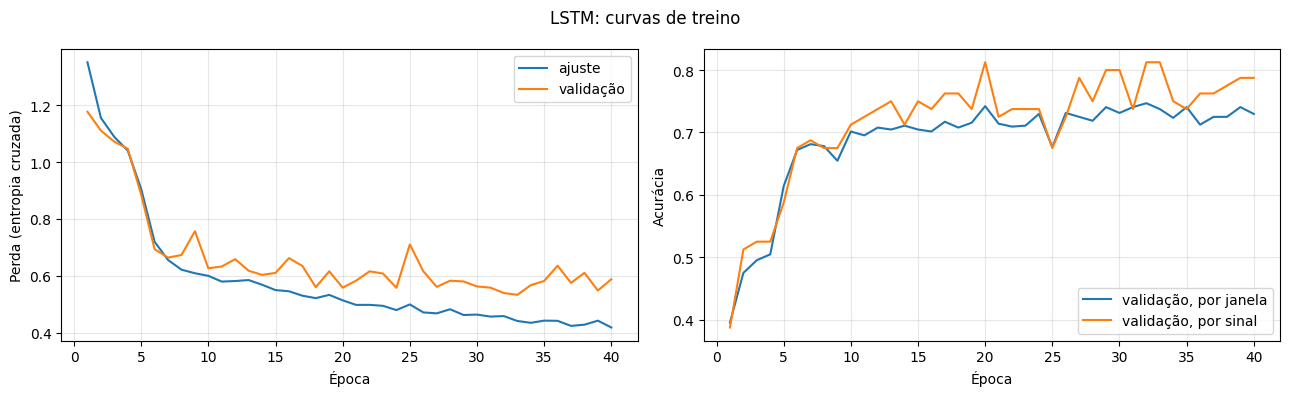

POR JANELA
              precision    recall  f1-score   support

           A      0.732     0.789     0.759       128
           B      0.920     0.812     0.863       128
           C      0.537     0.797     0.642       128
           D      0.552     0.289     0.379       128
           E      0.970     1.000     0.985       128

    accuracy                          0.738       640
   macro avg      0.742     0.738     0.726       640
weighted avg      0.742     0.738     0.726       640

POR SINAL
              precision    recall  f1-score   support

           A      0.929     0.812     0.867        16
           B      1.000     0.938     0.968        16
           C      0.583     0.875     0.700        16
           D      0.636     0.438     0.519        16
           E      1.000     1.000     1.000        16

    accuracy                          0.812        80
   macro avg      0.830     0.812     0.811        80
weighted avg      0.830     0.812     0.811        80



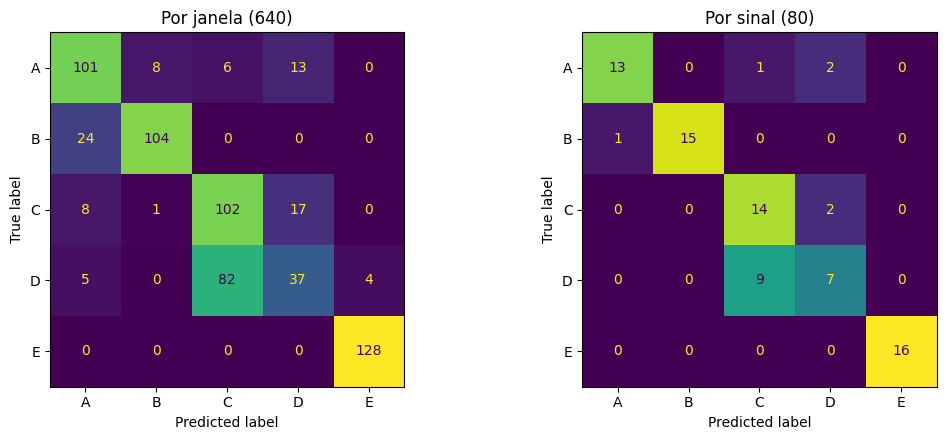

In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# 1) curvas de treino
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(historico.epoca, historico.perda_fit, label="ajuste")
axes[0].plot(historico.epoca, historico.perda_val, label="validação")
axes[0].set_xlabel("Época"); axes[0].set_ylabel("Perda (entropia cruzada)"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(historico.epoca, historico.acc_val_janela, label="validação, por janela")
axes[1].plot(historico.epoca, historico.acc_val_sinal, label="validação, por sinal")
axes[1].set_xlabel("Época"); axes[1].set_ylabel("Acurácia"); axes[1].legend(); axes[1].grid(alpha=0.3)
fig.suptitle("LSTM: curvas de treino")
plt.tight_layout(); plt.show()

# 2) métricas do melhor modelo na validação
_, probs, ys, ids = avaliar(modelo, loaders["val"])
pred_janela = probs.argmax(axis=1)
ids_s, probs_s = agregar_por_sinal(probs, ids)
y_s, pred_sinal = y_sinal[ids_s], probs_s.argmax(axis=1)

print("POR JANELA")
print(classification_report(ys, pred_janela, target_names=CLASSES, digits=3))
print("POR SINAL")
print(classification_report(y_s, pred_sinal, target_names=CLASSES, digits=3))

# 3) matrizes de confusão
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(ys, pred_janela, display_labels=CLASSES, ax=axes[0], colorbar=False)
axes[0].set_title("Por janela (640)")
ConfusionMatrixDisplay.from_predictions(y_s, pred_sinal, display_labels=CLASSES, ax=axes[1], colorbar=False)
axes[1].set_title("Por sinal (80)")
plt.tight_layout(); plt.show()

### Análise dos resultados

| Classe | Recall por janela | Recall por sinal | F1 por janela |
|---|---|---|---|
| A (saudável, olhos abertos) | 78,9 % | 81,2 % | 0,759 |
| B (saudável, olhos fechados) | 81,2 % | 93,8 % | 0,863 |
| C (interictal, hemisfério oposto) | 79,7 % | 87,5 % | 0,642 |
| D (interictal, zona epileptogênica) | **28,9 %** | **43,8 %** | **0,379** |
| E (ictal, crise) | 100 % | 100 % | 0,985 |
| **Acurácia global** | **73,8 %** | **81,2 %** | macro-F1 0,726 |

Leitura da matriz de confusão:

- **E (crise) é reconhecido perfeitamente** (128/128 janelas): a atividade ictal tem amplitude e ritmo muito diferentes de todo o resto.
- **A principal confusão é D → C**: 82 das 128 janelas de D são classificadas como C. Os dois conjuntos vêm dos mesmos pacientes, no mesmo estado (interictal, fora de crise), com eletrodos intracranianos. A diferença é só o local de registro (dentro da zona epileptogênica × hemisfério oposto), e ela é sutil no sinal.
- **A segunda confusão é B → A** (24 janelas): os dois são voluntários saudáveis com eletrodos de escalpo. A diferença principal é o ritmo alfa (8–13 Hz), mais forte com olhos fechados (B).
- Agregar por sinal melhora todas as classes, mas não resolve D × C (9 dos 16 sinais de D viram C).
- **Ressalva:** a validação tem só 16 sinais por classe, então um sinal a mais ou a menos muda o recall por sinal em 6,25 pontos.